# LSTM untuk Peramalan Jumlah Kunjungan Pasien

Langkah 5. LSTM univariat: memakai `W` hari terakhir untuk memprediksi hari berikutnya (one-step-ahead), sama seperti skema evaluasi SARIMA di notebook 04.

Aturan agar tidak terjadi kebocoran data:
- Split train/test identik dengan notebook 04 (`common.split_kronologis`).
- Skala MinMax **hanya di-fit pada train**.
- Validasi untuk early stopping dan pemilihan hiperparameter = **bagian akhir train** (kronologis, bukan acak). Test tidak dipakai untuk memilih apa pun.

In [1]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

import common as cm

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": .3})

y = cm.muat_data()
train, test = cm.split_kronologis(y)
n_train, n_test = len(train), len(test)
print("train:", n_train, "test:", n_test, "| TensorFlow", tf.__version__)

train: 1106 test: 276 | TensorFlow 2.21.0


## 1. Skala dan pembentukan window

Skala MinMax dari train. Window: baris `i` berisi `s[i : i+W]` dan targetnya `s[i+W]`. Target test memakai window yang boleh mencakup hari-hari terakhir train dan hari test sebelumnya (nilai aktual, sama seperti SARIMA one-step-ahead).

In [2]:
lo, hi = train.min(), train.max()
skala = lambda v: (v - lo) / (hi - lo)
balik = lambda v: v * (hi - lo) + lo
s_all = skala(y.values)          # seluruh deret, diskalakan dengan statistik train

def buat_window(W, target_idx):
    X = np.stack([s_all[t - W:t] for t in target_idx])[..., None]
    return X, s_all[target_idx]

VAL_FRAC = 0.15
def split_idx(W):
    idx_train_all = np.arange(W, n_train)
    n_val = int(len(idx_train_all) * VAL_FRAC)
    return idx_train_all[:-n_val], idx_train_all[-n_val:], np.arange(n_train, len(y))

tr, va, te = split_idx(28)
print("W=28 -> latih:", len(tr), "validasi:", len(va), "test:", len(te))

W=28 -> latih: 917 validasi: 161 test: 276


## 2. Model dan pemilihan hiperparameter

Arsitektur: `LSTM(units) -> Dense(1)`, loss MSE, Adam (lr 1e-3), early stopping (patience 20) pada loss validasi. Grid kecil: window `W` ∈ {14, 28} dan `units` ∈ {32, 64}; dipilih berdasarkan **RMSE validasi** (skala asli).

In [3]:
def bangun(W, units):
    m = keras.Sequential([keras.layers.Input((W, 1)),
                          keras.layers.LSTM(units),
                          keras.layers.Dense(1)])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    return m

def latih(W, units, seed):
    keras.utils.set_random_seed(seed)
    tr, va, _ = split_idx(W)
    Xtr, ytr = buat_window(W, tr); Xva, yva = buat_window(W, va)
    m = bangun(W, units)
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=300, batch_size=32, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True)])
    return m, h

def rmse_val(m, W):
    _, va, _ = split_idx(W)
    Xva, _ = buat_window(W, va)
    pred = balik(m.predict(Xva, verbose=0).ravel())
    return cm.rmse(y.values[va], pred)

grid = [(W, u) for W in (14, 28) for u in (32, 64)]
baris = []
for W, u in grid:
    m, h = latih(W, u, seed=0)
    baris.append({"W": W, "units": u, "epoch terbaik": int(np.argmin(h.history["val_loss"])) + 1,
                  "RMSE validasi": rmse_val(m, W)})
tabel_grid = pd.DataFrame(baris)
tabel_grid.round(2)

,W,units,epoch terbaik,RMSE validasi
0,14,32,85,189.46
1,14,64,110,178.44
2,28,32,112,153.36
3,28,64,36,171.31


In [4]:
terbaik = tabel_grid.loc[tabel_grid["RMSE validasi"].idxmin()]
W_b, U_b = int(terbaik["W"]), int(terbaik["units"])
print(f"Hiperparameter terpilih: W={W_b}, units={U_b}")

Hiperparameter terpilih: W=28, units=32


## 3. Latih ulang dengan beberapa seed

Inisialisasi acak membuat hasil LSTM bervariasi antar run. Model terpilih dilatih dengan 5 seed; yang dilaporkan sebagai hasil LSTM adalah **rata-rata prediksi kelima seed** (ensemble), dan sebaran antar seed ditampilkan agar stabilitasnya terlihat.

In [5]:
SEEDS = [0, 1, 2, 3, 4]
_, _, te = split_idx(W_b)
Xte, _ = buat_window(W_b, te)
aktual = y.values[te]

pred_seed, ep = {}, {}
for sd in SEEDS:
    m, h = latih(W_b, U_b, seed=sd)
    pred_seed[sd] = balik(m.predict(Xte, verbose=0).ravel())
    ep[sd] = int(np.argmin(h.history["val_loss"])) + 1

per_seed = pd.DataFrame({f"seed {sd}": cm.metrik(aktual, p) for sd, p in pred_seed.items()}).T
per_seed["epoch terbaik"] = pd.Series({f"seed {sd}": e for sd, e in ep.items()})
per_seed.round(2)

,RMSE,MAE,MAPE (%),epoch terbaik
seed 0,232.46,143.41,28.61,112
seed 1,232.98,147.49,28.53,139
seed 2,252.50,169.25,32.12,90
seed 3,234.51,145.44,31.55,119
seed 4,235.25,152.30,33.71,73


In [6]:
pred_ens = np.mean(list(pred_seed.values()), axis=0)
ringkas = pd.DataFrame({
    "Rata-rata antar seed": per_seed[["RMSE", "MAE", "MAPE (%)"]].mean(),
    "Simpangan baku antar seed": per_seed[["RMSE", "MAE", "MAPE (%)"]].std(),
    "Ensemble (rata-rata prediksi)": pd.Series(cm.metrik(aktual, pred_ens)),
})
ringkas.round(2)

,Rata-rata antar seed,Simpangan baku antar seed,Ensemble (rata-rata prediksi)
RMSE,237.54,8.44,233.62
MAE,151.58,10.41,146.82
MAPE (%),30.91,2.28,29.32


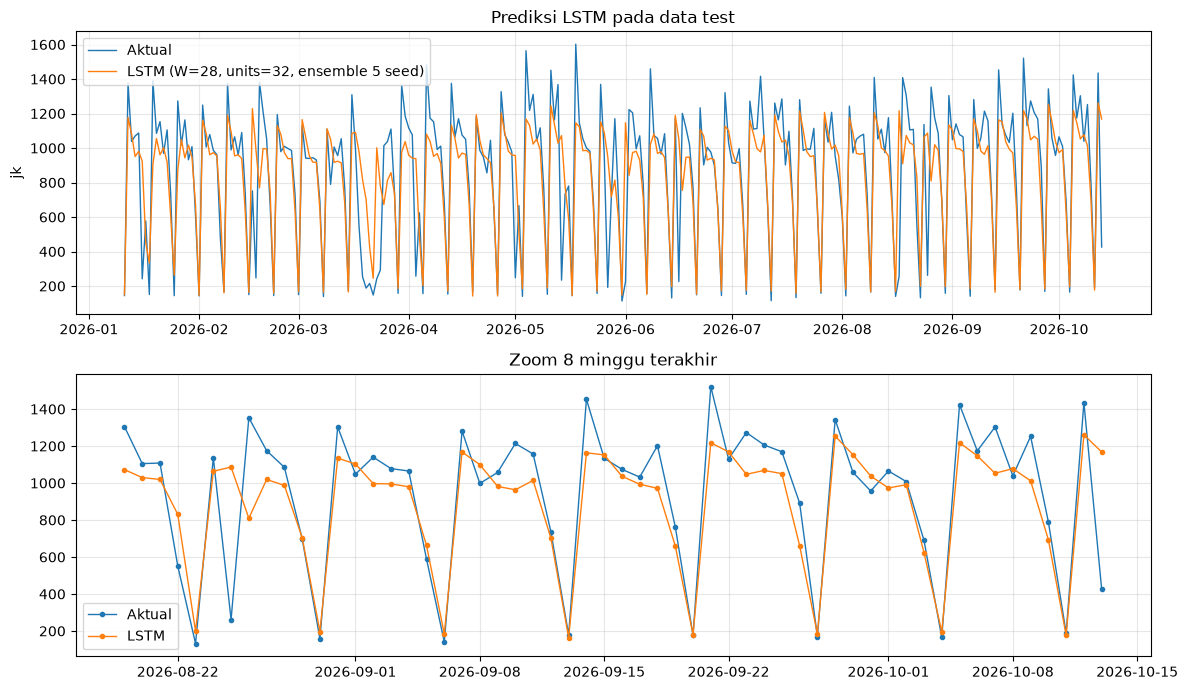

In [7]:
p = pd.Series(pred_ens, index=test.index)
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].plot(test, lw=1, label="Aktual")
axes[0].plot(p, lw=1, label=f"LSTM (W={W_b}, units={U_b}, ensemble 5 seed)")
axes[0].set(title="Prediksi LSTM pada data test", ylabel="jk"); axes[0].legend()
axes[1].plot(test.index[-56:], test.iloc[-56:], marker="o", ms=3, lw=1, label="Aktual")
axes[1].plot(p.iloc[-56:], marker="o", ms=3, lw=1, label="LSTM")
axes[1].set(title="Zoom 8 minggu terakhir"); axes[1].legend()
plt.tight_layout(); plt.show()

In [8]:
cm.HASIL_DIR.mkdir(parents=True, exist_ok=True)
out = pd.DataFrame({"aktual": test, "lstm": p})
for sd, pr in pred_seed.items():
    out[f"lstm_seed{sd}"] = pr
out.to_csv(cm.HASIL_DIR / "pred_lstm.csv")
tabel_grid.to_csv(cm.HASIL_DIR / "lstm_grid.csv", index=False)
print("Disimpan di", cm.HASIL_DIR)

Disimpan di D:\Kuliah\Semester 5\ADW\sarima\data\hasil
